# Assignment 05 – Evaluation: Beyond Accuracy

## 1. Introduction

In this assignment, I evaluate machine learning models trained on the Medical Appointment No Shows dataset.

The objective is to evaluate how effectively the models predict whether a patient will attend or miss an appointment.

I will go beyond accuracy by examining the confusion matrix, precision, recall, F1-score, cross-validation, and Scikit-Learn pipelines.

I will also compare multiple models and recommend one based on its performance and limitations.

## 2. Dataset Loading and Preparation

I am using the Medical Appointment No Shows dataset from Kaggle, which contains patient information and appointment attendance records.

In [5]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('/content/KaggleV2-May-2016.csv')

# Display dataset information
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (110527, 14)

First five rows:


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No



Column names:
['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show']


## 3. Feature and Target Preparation

The target variable is `No-show`, which indicates whether a patient attended or missed an appointment.

I use the same nine input features from Assignment 04 to maintain consistency during evaluation.

The Gender column is converted into numerical columns using one-hot encoding.

PatientId, AppointmentID, Neighbourhood, and the target column are excluded from the input features to avoid irrelevant identifiers, potential geographical bias, and target leakage.

In [6]:
valid_age_median = df.loc[df['Age'] >= 0, 'Age'].median()
df.loc[df['Age'] < 0, 'Age'] = valid_age_median

features = ['Age','Gender','Scholarship','Hipertension','Diabetes','Alcoholism','Handcap','SMS_received']

X = df[features].copy()

X = pd.get_dummies(X, columns=['Gender'], dtype=int)

y = df['No-show']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (110527, 9)
Target shape: (110527,)

Feature columns:
['Age', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'Gender_F', 'Gender_M']

Target distribution:
No-show
No     88208
Yes    22319
Name: count, dtype: int64


## 4. Confusion Matrix and Classification Metrics

A confusion matrix compares the actual target values with the model's predictions.

It helps identify:
- True Positive (TP)
- True Negative (TN)
- False Positive (FP)
- False Negative (FN)

I will first evaluate the Logistic Regression model using the default classification threshold.

Confusion Matrix:
[[17669     0]
 [ 4437     0]]


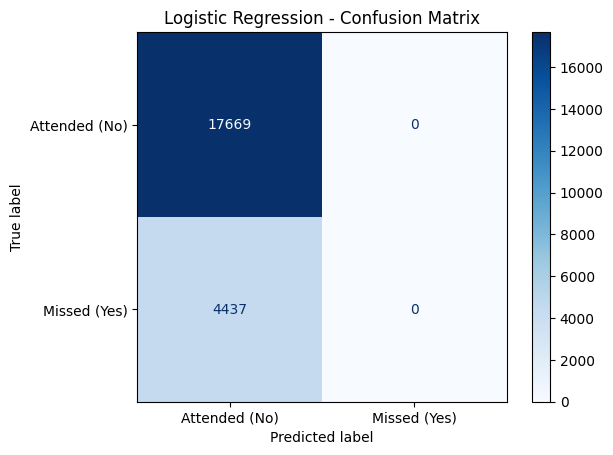

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

# Make predictions
y_pred = lr_model.predict(X_test)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Attended (No)', 'Missed (Yes)']
)

display.plot(cmap='Blues')
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### Understanding the Confusion Matrix

For this assignment, `Yes` (missed appointment) is the positive class, and `No` (attended appointment) is the negative class.

- True Positive (TP): The model predicts `Yes`, and the patient actually misses the appointment.
- True Negative (TN): The model predicts `No`, and the patient actually attends the appointment.
- False Positive (FP): The model predicts `Yes`, but the patient actually attends.
- False Negative (FN): The model predicts `No`, but the patient actually misses the appointment.

In my Logistic Regression confusion matrix:
- TN = 17,669
- FP = 0
- FN = 4,437
- TP = 0

The model failed to identify any missed appointments.

## 5. Precision, Recall and F1-Score

Accuracy alone does not provide sufficient information when working with an imbalanced dataset.

I calculate precision, recall, and F1-score to understand how effectively the model identifies patients who miss appointments.

The positive class is `Yes`, representing patients who missed their appointments.

In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred, pos_label='Yes', zero_division=0)
recall = recall_score(y_test, y_pred, pos_label='Yes', zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label='Yes', zero_division=0)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000


### Interpretation of Classification Metrics

The Logistic Regression model achieved approximately 79.93% accuracy, but its precision, recall, and F1-score for the positive class (`Yes`) were all zero.

The confusion matrix shows that the model predicted every test record as `No`, meaning it failed to identify any patients who missed their appointments.

Although the accuracy appears reasonable, the model is ineffective at identifying missed appointments. This highlights the limitation of relying only on accuracy when evaluating an imbalanced classification dataset.

### False Positive vs False Negative in Healthcare

A false negative can be more harmful in this appointment prediction scenario because the model predicts that a patient will attend, but the patient actually misses the appointment.

The hospital may therefore miss an opportunity to send an additional reminder or take preventive action. This can lead to unused appointment slots and inefficient resource allocation.

However, false positives also have costs, such as unnecessary reminders and additional staff effort. The relative impact depends on how the prediction system is used.

## 6. Five-Fold Cross-Validation

Cross-validation evaluates model performance across multiple training and validation splits.

I use 5-fold cross-validation to evaluate Logistic Regression and compare the mean and standard deviation of the scores with the single train-test split.

In [9]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    lr_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Cross-validation scores:", cv_scores)
print(f"Mean accuracy: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

single_split_accuracy = lr_model.score(X_test, y_test)

print(f"\nSingle split accuracy: {single_split_accuracy:.4f}")

Cross-validation scores: [0.79806387 0.79806387 0.79809998 0.79805474 0.79805474]
Mean accuracy: 0.7981
Standard deviation: 0.0000

Single split accuracy: 0.7993


### Cross-Validation Results and Interpretation

The Logistic Regression model achieved a mean accuracy of approximately 79.81% across five folds, with very low standard deviation.

The single train-test split accuracy was approximately 79.93%, which is close to the cross-validation mean. This suggests that the model's accuracy is consistent across different data splits.

However, consistent accuracy does not mean the model is effective at identifying missed appointments. The model continues to favour the majority class and has zero recall for the positive class.

## 7. Building a Scikit-Learn Pipeline

A Scikit-Learn pipeline combines preprocessing and model training into a single object.

I use StandardScaler to scale numerical features and Logistic Regression as the classification model.

The pipeline ensures that preprocessing is fitted only on the training data during cross-validation, preventing data leakage.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline_scores = cross_val_score(
    lr_pipeline,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Pipeline cross-validation scores:", pipeline_scores)
print(f"Mean accuracy: {pipeline_scores.mean():.4f}")
print(f"Standard deviation: {pipeline_scores.std():.4f}")

Pipeline cross-validation scores: [0.79806387 0.79806387 0.79809998 0.79805474 0.79805474]
Mean accuracy: 0.7981
Standard deviation: 0.0000


### Pipeline Results and Interpretation

The Logistic Regression pipeline achieved a mean accuracy of approximately 79.81% across five folds, with very low variation between folds.

The results are almost identical to the earlier Logistic Regression evaluation. This indicates that applying feature scaling did not significantly change the model's accuracy.

The pipeline helps prevent data leakage by fitting the scaler separately within each training fold before transforming its validation fold.

## 8. Model Evaluation and Comparison

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Majority Baseline': DummyClassifier(strategy='most_frequent'),

    'Logistic Regression Pipeline': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000))
    ])
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, pos_label='Yes', zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, pos_label='Yes', zero_division=0
        ),
        'F1-score': f1_score(
            y_test, predictions, pos_label='Yes', zero_division=0
        )
    })

# comparison table
evaluation_df = pd.DataFrame(results)
print(evaluation_df.round(4))

                          Model  Accuracy  Precision  Recall  F1-score
0           Logistic Regression    0.7993     0.0000  0.0000    0.0000
1                 Decision Tree    0.7970     0.3775  0.0174    0.0332
2             Majority Baseline    0.7993     0.0000  0.0000    0.0000
3  Logistic Regression Pipeline    0.7993     0.0000  0.0000    0.0000


## 9. Final Model Recommendation

None of the evaluated models is sufficiently reliable for predicting missed appointments in a real healthcare setting. The Decision Tree is comparatively more useful for identifying no-shows because it achieves a non-zero precision of 37.75% and recall of 1.74%, but it still misses almost all actual no-shows. Further improvements, such as handling class imbalance, feature engineering, and hyperparameter tuning, are necessary before considering any model for practical use.